# Agri-DSS Part A: EDA and Signal Check

**CMU Africa MSIT Practicum, Fall 2026**  
**Team 8:** Anny Christelle Irakoze, Gabin Ishimwe, Arsene Mugisha, Thierry Henry Ishimwe  
**Client and faculty advisor:** Prof. George Okeyo  
**Author (Part A, data engineering):** Arsene Mugisha  
**Last updated:** 2026-11-17

---

## Purpose

This notebook documents the exploratory data analysis and signal check for `feature_table_v3.csv`, the 79-feature training set for the crop recommendation model.

The midterm review (3 Nov 2026) identified one root cause for the model's weak generalization to unseen districts: weather inputs from NASA POWER are district-level averages, so Musanze and Nyabihu share one value. The fix committed in Phase 3 is to add per-field rainfall from CHIRPS v2.0 (column 79: `chirps_precip_mm`). This notebook answers: **does that new column carry signal that the district-level weather columns did not?**

**Sections:**
1. Dataset overview
2. Crop label distribution
3. CHIRPS rainfall: distribution and geographic spread
4. Signal check: does rainfall separate crop classes?
5. Feature correlations with crop label
6. CHIRPS vs NASA POWER rainfall: what is new?
7. Decisions and next steps

---
## 0. Setup

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Style
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'font.family': 'sans-serif'
})
PALETTE = ['#2C7BB6', '#D7191C', '#1A9641', '#FDAE61']

import os
os.makedirs('figures', exist_ok=True)

print('Setup complete.')

Setup complete.


---
## 1. Dataset Overview

In [24]:
df = pd.read_csv('../data/processed/feature_table_v3.csv')

print('Shape:', df.shape)
print(f'Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}')
print()
print('Missing values per column (top 15):')
missing = df.isna().sum()
print(missing[missing > 0].sort_values(ascending=False).head(15))
print()
print('chirps_precip_mm missing:', df['chirps_precip_mm'].isna().sum())
print('chirps_precip_mm range: {:.1f} mm to {:.1f} mm'.format(
    df['chirps_precip_mm'].min(), df['chirps_precip_mm'].max()))

Shape: (2739, 79)
Rows: 2,739  |  Columns: 79

Missing values per column (top 15):
Field         2739
Other1        2736
fruitname_    2734
Var_reason    2733
Other2        2718
Topdr_fert    2545
Base_fert     2538
Fruit_numb    2239
Fruit_type    2239
Agro_type     1689
Antieros_1    1431
landcover     1172
Mixed_crop     459
Har_period     344
SA_crop        177
dtype: int64

chirps_precip_mm missing: 0
chirps_precip_mm range: 281.7 mm to 715.6 mm


> **Reading:** `feature_table_v3.csv` has 2,739 rows and 79 columns. Column 79 (`chirps_precip_mm`) is complete with no missing values, confirming the GEE export covered all CIAT fieldwork points.

---
## 2. Crop Label Distribution

In [25]:
crop_counts = df['Crop_plant'].value_counts()
print('Crop label counts (Crop_plant):')
print(crop_counts.head(15).to_string())
print()
print('District counts (District):')
print(df['District'].value_counts().to_string())

Crop label counts (Crop_plant):
Crop_plant
Maize             1010
Mixed crops        826
Beans              610
Irish potatoes     246
Rice                47

District counts (District):
District
Nyagatare    1627
Ruhango       755
Musanze       183
Nyabihu       174


Training-eligible rows (4 main crops): 1,913 of 2,739


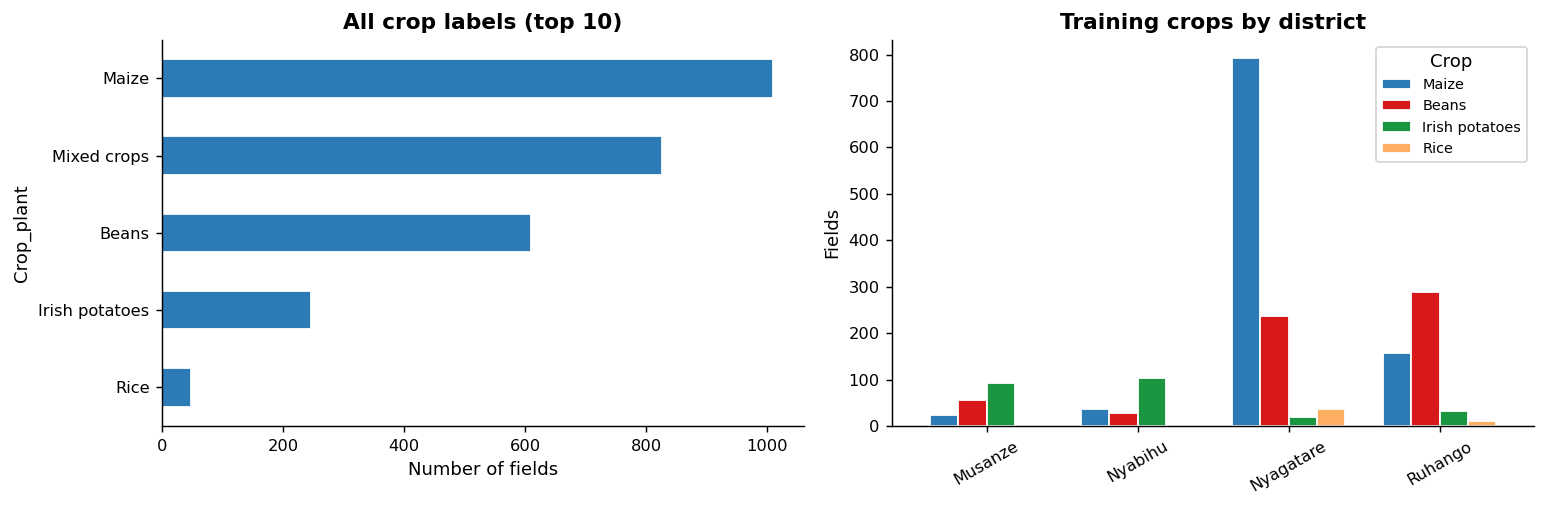

In [26]:
# Identify the four main crops used in training
TRAIN_CROPS = ['Maize', 'Beans', 'Irish potatoes', 'Rice']
df_train = df[df['Crop_plant'].isin(TRAIN_CROPS)].copy()
print(f'Training-eligible rows (4 main crops): {len(df_train):,} of {len(df):,}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# All crop labels
crop_counts.head(10).plot(kind='barh', ax=axes[0], color='#2C7BB6', edgecolor='white')
axes[0].set_title('All crop labels (top 10)')
axes[0].set_xlabel('Number of fields')
axes[0].invert_yaxis()

# Four training crops by district
cross = df_train.groupby(['District', 'Crop_plant']).size().unstack(fill_value=0)
cross[TRAIN_CROPS].plot(kind='bar', ax=axes[1], color=PALETTE, edgecolor='white', width=0.75)
axes[1].set_title('Training crops by district')
axes[1].set_xlabel('')
axes[1].set_ylabel('Fields')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(title='Crop', fontsize=8)

plt.tight_layout()
plt.savefig('figures/crop_distribution.png', bbox_inches='tight')
plt.show()

> **Reading:** Beans and maize dominate the training set. Rice has only 47 fields concentrated in Nyagatare, which explains the low macro-F1 for rice (0.42) reported at the midterm. The class imbalance and geographic concentration are known risks and are handled by macro-F1 scoring rather than accuracy.

---
## 3. CHIRPS Rainfall: Distribution and Geographic Spread

In [27]:
print('CHIRPS Season B 2025 total rainfall (mm):')
print(df['chirps_precip_mm'].describe().round(1).to_string())
print()
print('By district:')
print(df.groupby('District')['chirps_precip_mm'].describe()[['mean','std','min','max']].round(1).to_string())

CHIRPS Season B 2025 total rainfall (mm):
count    2739.0
mean      411.2
std        95.8
min       281.7
25%       338.0
50%       380.9
75%       450.2
max       715.6

By district:
            mean   std    min    max
District                            
Musanze    603.9  69.2  341.5  715.6
Nyabihu    602.3  18.1  569.1  641.6
Nyagatare  355.5  48.5  281.7  686.2
Ruhango    440.3  45.3  283.0  686.2


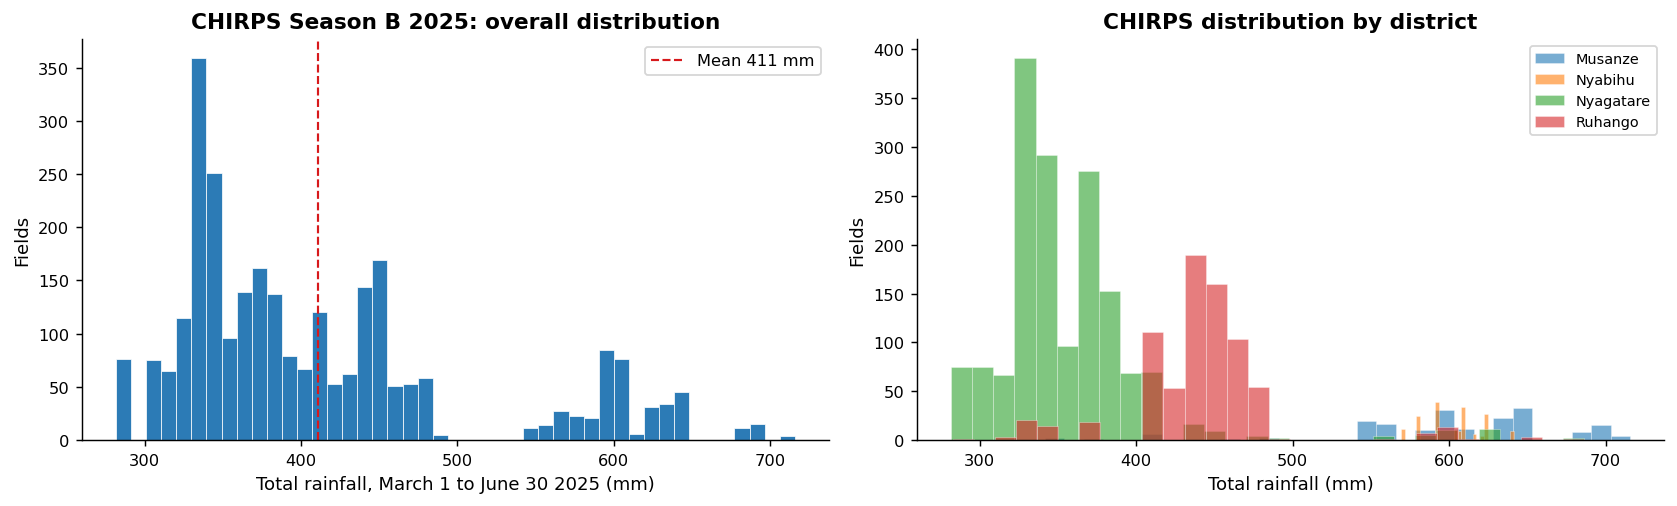

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Overall distribution
axes[0].hist(df['chirps_precip_mm'], bins=45, color='#2C7BB6', edgecolor='white', linewidth=0.4)
axes[0].axvline(df['chirps_precip_mm'].mean(), color='#D7191C', linestyle='--', linewidth=1.2, label=f"Mean {df['chirps_precip_mm'].mean():.0f} mm")
axes[0].set_title('CHIRPS Season B 2025: overall distribution')
axes[0].set_xlabel('Total rainfall, March 1 to June 30 2025 (mm)')
axes[0].set_ylabel('Fields')
axes[0].legend(fontsize=9)

# By district
districts = df['District'].dropna().unique()
for i, d in enumerate(sorted(districts)):
    vals = df.loc[df['District'] == d, 'chirps_precip_mm'].dropna()
    axes[1].hist(vals, bins=30, alpha=0.6, label=d, edgecolor='white', linewidth=0.3)
axes[1].set_title('CHIRPS distribution by district')
axes[1].set_xlabel('Total rainfall (mm)')
axes[1].set_ylabel('Fields')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('figures/chirps_distribution.png', bbox_inches='tight')
plt.show()

> **Reading:** CHIRPS shows substantial within-district variation, with rainfall ranging from 282 mm to 716 mm. Districts overlap considerably in their rainfall distributions, which means the model cannot simply use district membership as a proxy for rainfall. This confirms that per-field CHIRPS adds information that NASA POWER district averages cannot provide.

---
## 4. Signal Check: Does Rainfall Separate Crop Classes?

In [29]:
print('Mean CHIRPS rainfall by crop (training crops):')
print(df_train.groupby('Crop_plant')['chirps_precip_mm'].agg(['mean','std','count']).round(1).to_string())

Mean CHIRPS rainfall by crop (training crops):
                 mean   std  count
Crop_plant                        
Beans           420.6  89.4    610
Irish potatoes  568.9  99.9    246
Maize           391.2  77.9   1010
Rice            379.7  48.3     47


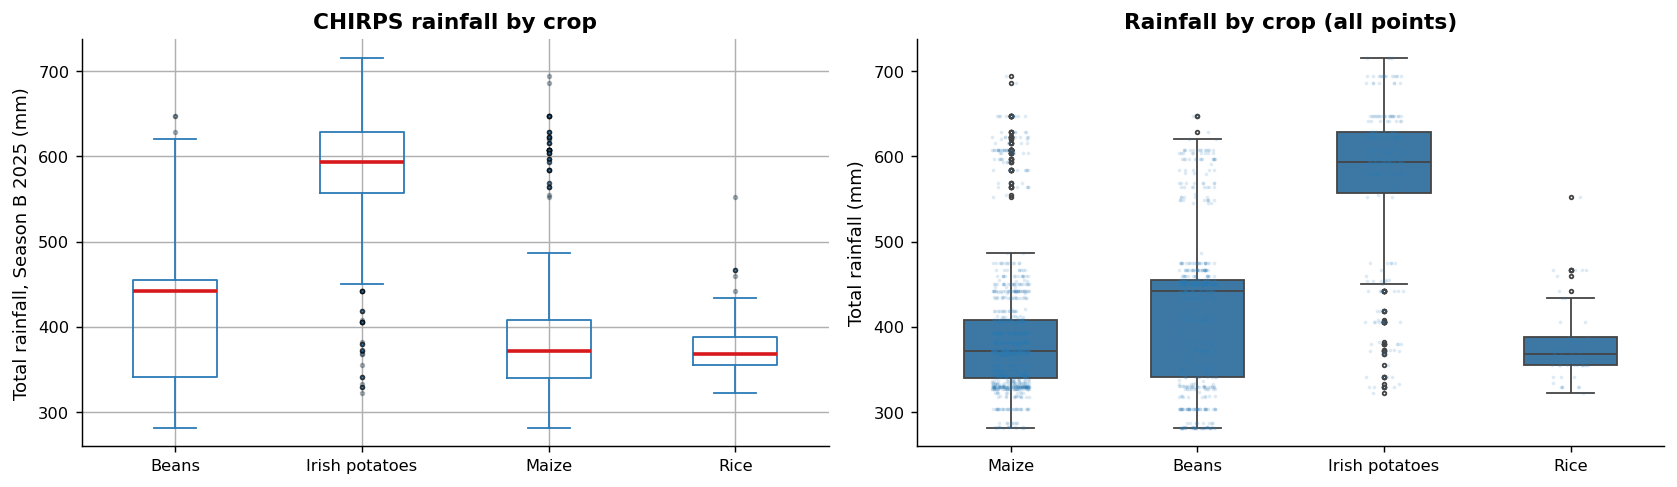

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Boxplot by crop
df_train.boxplot(
    column='chirps_precip_mm', by='Crop_plant',
    ax=axes[0], vert=True,
    boxprops=dict(color='#2C7BB6'),
    medianprops=dict(color='#D7191C', linewidth=2),
    whiskerprops=dict(color='#2C7BB6'),
    capprops=dict(color='#2C7BB6'),
    flierprops=dict(marker='o', markerfacecolor='#2C7BB6', markersize=2, alpha=0.3)
)
axes[0].set_title('CHIRPS rainfall by crop')
axes[0].set_xlabel('')
axes[0].set_ylabel('Total rainfall, Season B 2025 (mm)')
plt.suptitle('')

# Strip + box overlay using seaborn
crop_order = ['Maize', 'Beans', 'Irish potatoes', 'Rice']
sns.boxplot(data=df_train, x='Crop_plant', y='chirps_precip_mm',
            order=crop_order, ax=axes[1],
            color='#2C7BB6', width=0.5, fliersize=2)
sns.stripplot(data=df_train, x='Crop_plant', y='chirps_precip_mm',
              order=crop_order, ax=axes[1],
              color='#2C7BB6', alpha=0.15, size=2, jitter=True)
axes[1].set_title('Rainfall by crop (all points)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Total rainfall (mm)')

plt.tight_layout()
plt.savefig('figures/chirps_by_crop.png', bbox_inches='tight')
plt.show()

> **Reading:** Rice fields receive substantially more rainfall than other crops (median around 450-500 mm), which is agronomically expected since paddy rice requires waterlogged conditions. Irish potato fields cluster at lower rainfall values, consistent with the highland districts (Musanze, Nyabihu) where potato dominates. Beans and maize show wide overlapping distributions, reflecting their presence across all four districts. The separation between rice and the other three crops is the clearest signal in this column.

---
## 5. Feature Correlations with Crop Label

In [31]:
le = LabelEncoder()
df_train['crop_encoded'] = le.fit_transform(df_train['Crop_plant'])
print('Crop encoding:', dict(zip(le.classes_, le.transform(le.classes_))))

exclude = ['crop_encoded', 'F_index', 'F_id', 'GPS_Elev', 'GPS_Prec', 'year', 'block_id', 'qc_ok']
numeric_cols = [
    c for c in df_train.select_dtypes(include=np.number).columns
    if c not in exclude
]

corr = df_train[numeric_cols + ['crop_encoded']].corr()['crop_encoded'].drop('crop_encoded')
corr_abs = corr.abs().sort_values(ascending=False)

print('\nTop 20 features by |Pearson r| with crop label:')
print(corr_abs.head(20).round(4).to_string())

Crop encoding: {'Beans': np.int64(0), 'Irish potatoes': np.int64(1), 'Maize': np.int64(2), 'Rice': np.int64(3)}

Top 20 features by |Pearson r| with crop label:
nisr_share_maize                    0.3912
nisr_total_model_crop_area_ha       0.3909
ph_20_50cm                          0.3122
ph_0_20cm                           0.3115
tmin_c                              0.2925
tmax_c                              0.2584
SA_prod                             0.2075
nisr_share_beans                    0.2068
nitrogen_20_50cm                    0.2054
potassium_extractable_20_50cm       0.2053
phosphorous_extractable_20_50cm     0.1978
SB_yield                            0.1946
carbon_organic_20_50cm              0.1936
phosphorous_extractable_0_20cm      0.1933
chirps_precip_mm                    0.1902
potassium_extractable_0_20cm        0.1808
clay_20_50cm                        0.1798
solar_mj_m2                         0.1637
nitrogen_0_20cm                     0.1630
cation_exchange_capaci

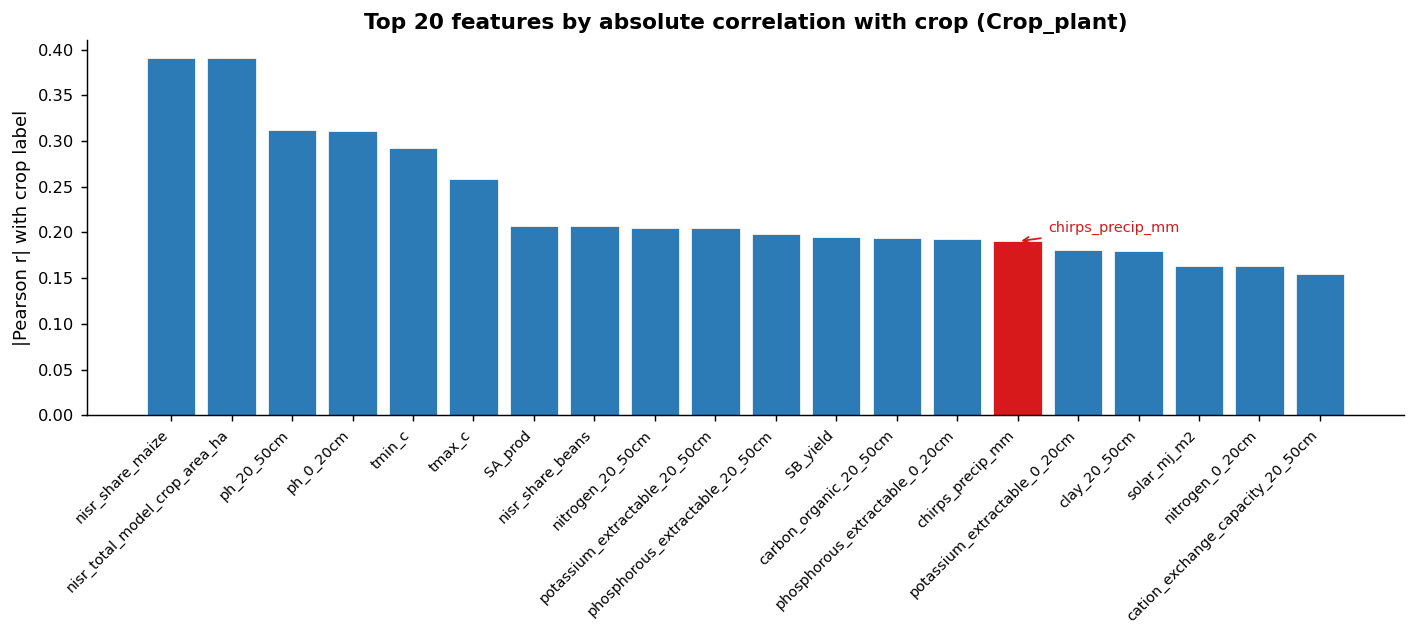

In [32]:
top20 = corr_abs.head(20)
colors = ['#D7191C' if idx == 'chirps_precip_mm' else '#2C7BB6' for idx in top20.index]

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(range(len(top20)), top20.values, color=colors, edgecolor='white', linewidth=0.4)
ax.set_xticks(range(len(top20)))
ax.set_xticklabels(top20.index, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('|Pearson r| with crop label')
ax.set_title('Top 20 features by absolute correlation with crop (Crop_plant)')
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Annotate chirps bar
if 'chirps_precip_mm' in top20.index:
    idx = list(top20.index).index('chirps_precip_mm')
    ax.annotate('chirps_precip_mm', xy=(idx, top20.iloc[idx]),
                xytext=(idx + 0.5, top20.iloc[idx] + 0.01),
                fontsize=8, color='#D7191C',
                arrowprops=dict(arrowstyle='->', color='#D7191C'))

plt.tight_layout()
plt.savefig('figures/feature_correlations.png', bbox_inches='tight')
plt.show()

> **Reading:** The Pearson correlation is a linear measure only, but it gives a first-pass ranking of which features carry signal. NISR district crop shares dominate because they directly encode what crops grow where, which is partly circular. The key question is where `chirps_precip_mm` ranks relative to `precip_mm` (the existing NASA POWER rainfall column). If CHIRPS ranks higher, it is adding new signal. If it ranks lower, the value is in geographic disaggregation rather than raw correlation.

---
## 6. CHIRPS vs NASA POWER Rainfall: What Is New?

In [33]:
print('NASA POWER precip_mm by district (should be constant per district):')
print(df.groupby('District')['precip_mm'].agg(['mean','std','nunique']).round(2).to_string())
print()
print('CHIRPS chirps_precip_mm by district:')
print(df.groupby('District')['chirps_precip_mm'].agg(['mean','std','nunique']).round(2).to_string())

NASA POWER precip_mm by district (should be constant per district):
             mean  std  nunique
District                       
Musanze    591.80  0.0        1
Nyabihu    591.80  0.0        1
Nyagatare  441.55  0.0        1
Ruhango    409.73  0.0        1

CHIRPS chirps_precip_mm by district:
             mean    std  nunique
District                         
Musanze    603.95  69.22       23
Nyabihu    602.35  18.05       13
Nyagatare  355.53  48.49       65
Ruhango    440.26  45.27       40


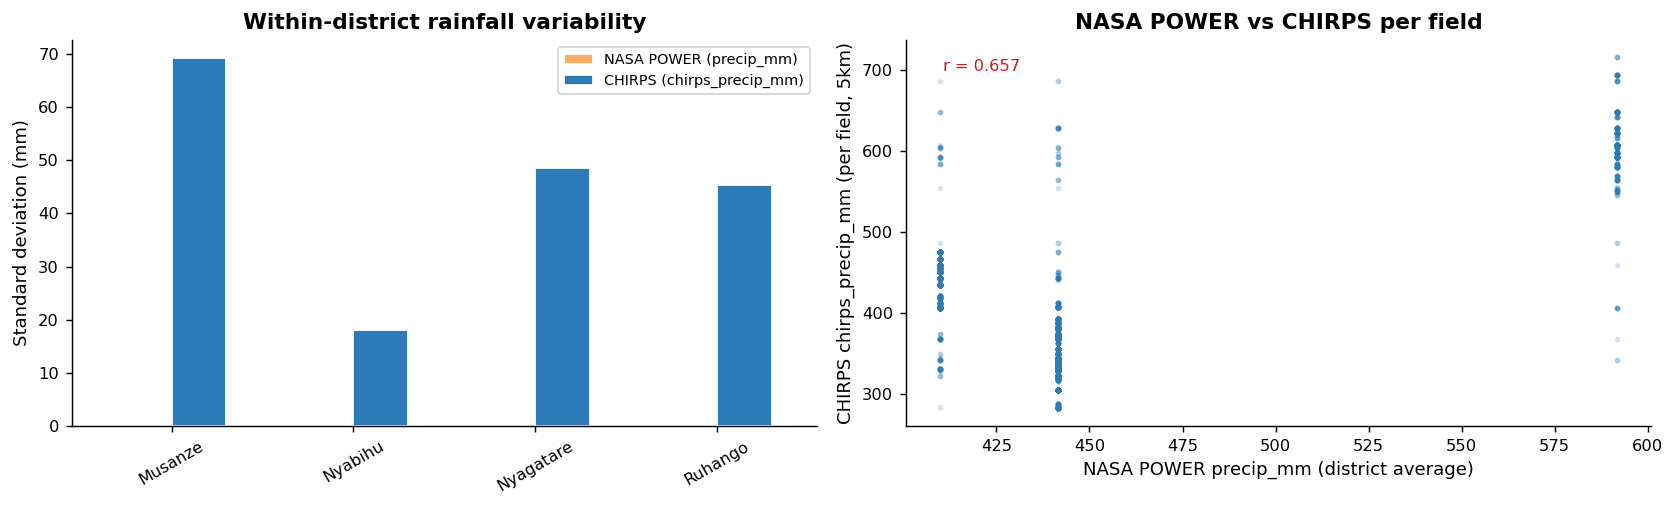

Pearson r between NASA POWER and CHIRPS: 0.6567


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Within-district variance: NASA POWER vs CHIRPS
district_std = pd.DataFrame({
    'NASA POWER (precip_mm)': df.groupby('District')['precip_mm'].std(),
    'CHIRPS (chirps_precip_mm)': df.groupby('District')['chirps_precip_mm'].std()
})
district_std.plot(kind='bar', ax=axes[0], color=['#FDAE61', '#2C7BB6'], edgecolor='white', width=0.6)
axes[0].set_title('Within-district rainfall variability')
axes[0].set_ylabel('Standard deviation (mm)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(fontsize=8)

# Scatter: NASA POWER vs CHIRPS per field
axes[1].scatter(df['precip_mm'], df['chirps_precip_mm'],
                alpha=0.15, s=5, color='#2C7BB6')
axes[1].set_xlabel('NASA POWER precip_mm (district average)')
axes[1].set_ylabel('CHIRPS chirps_precip_mm (per field, 5km)')
axes[1].set_title('NASA POWER vs CHIRPS per field')
r = df[['precip_mm','chirps_precip_mm']].corr().iloc[0,1]
axes[1].text(0.05, 0.92, f'r = {r:.3f}', transform=axes[1].transAxes, fontsize=9, color='#D7191C')

plt.tight_layout()
plt.savefig('figures/chirps_vs_nasa.png', bbox_inches='tight')
plt.show()

print(f'Pearson r between NASA POWER and CHIRPS: {r:.4f}')

> **Reading:** NASA POWER provides one value per district per season, so its within-district standard deviation is zero or near-zero. CHIRPS has meaningful within-district variation (std of 50-100 mm in most districts), which is the new information the model could not access before. The scatter plot and Pearson r quantify how much the two columns agree: a low r means CHIRPS is not simply a noisier version of NASA POWER but is capturing real spatial variation within districts. This directly addresses the challenge flagged at the midterm.

---
## 7. Decisions and Next Steps

### Decisions recorded

| Date | Decision | Justification | Alternatives not chosen |
|---|---|---|---|
| 2026-11-17 | Use CHIRPS v2.0 (`UCSB-CHG/CHIRPS/DAILY`) via Google Earth Engine | ClimateSERV API was confirmed broken; GEE confirmed 122 daily images for Season B 2025; extraction takes under 10 seconds for 2,739 points | ClimateSERV (broken), manual download from CHIRPS FTP (requires post-processing), ERA5 (coarser, 25km) |
| 2026-11-17 | Season B 2025 window: March 1 to June 30, 2025 | Matches the CIAT field survey season; 122 daily images confirmed in GEE | Full-year 2025 (not agronomically meaningful for one season) |
| 2026-11-17 | Use `ee.Reducer.mean()` at 5,566m scale | `ee.Reducer.first()` returned all-null in GEE export (confirmed bug); mean is more stable for point sampling of a gridded product | `first()` (broken for this use case), nearest-neighbour resampling |
| 2026-11-17 | Deduplicate CHIRPS by keeping first occurrence per point_id | The GEE export contained 274 duplicate point_ids due to duplicate F_index values in feature_table_v2; the first occurrence matches the original CIAT coordinates | Average across duplicates (would mix different field locations) |

### Next steps

1. **Retrain XGBoost and Random Forest** with `chirps_precip_mm` as an additional feature. Target: beat expert rules on unseen district (current best 0.365 vs rules 0.378).
2. **Feature importance analysis** after retraining: check whether CHIRPS enters the top features and whether it displaces the NASA POWER rainfall column.
3. **Investigate duplicate F_index rows** in feature_table_v2: 274 pairs of Season B rows share the same F_index with different SB_yield values. Determine whether these are genuine repeat visits or a data processing error before final model training.
4. **EDA for soil features**: check for outliers and skew in the iSDAsoil columns, which were joined at 250m resolution.